# Project 1, Privacy blur

**AI Fundamentals, Session 3**

Film a lecture, a street or an event and you film faces. Under the GDPR a face is personal
data. In this project you build a tool that finds every face in a photo, or in your live
webcam, and hides it before anything is stored or shared.

You will:

- **A** Download a face detector somebody else trained, and run it on a photo
- **B** Read what it returns, boxes and scores, and choose a threshold
- **C** Blur, pixelate or black out every face it found
- **D** Run it live on your webcam
- **E** Swap in a general detector that knows 80 kinds of object, and count people

The point: you train nothing here. A trained model is a component you download and plug
in. Your job is choosing the threshold, and finding out where it fails.

In [2]:
# Every notebook starts by importing the tools it needs.
# "import x" makes the package x available; "from x import y" takes one piece out of it.

import io  # turns a picture into bytes in memory, for showing it

import cv2  # OpenCV, the classic computer vision library
import matplotlib.pyplot as plt  # plotting
import numpy as np  # an image is a grid of numbers, and numpy handles grids
from pathlib import Path  # file paths that work on every operating system
from huggingface_hub import hf_hub_download  # downloads a file from huggingface.co, once
from IPython.display import Image as Picture  # shows a picture in the notebook
from PIL import Image  # opens and converts image files

cv2.utils.logging.setLogLevel(cv2.utils.logging.LOG_LEVEL_ERROR)  # hide OpenCV's harmless warnings
print("ready")

ready


---
## Part A, a detector somebody else trained

Hugging Face is to trained models what GitHub is to code: a public shelf holding millions
of them. We take **YuNet**, a face detector published there by the OpenCV team.
It is a small convolutional network, the kind you saw in the vision part of the course,
and the whole thing is 230 kB.

In [3]:
# hf_hub_download(repository, file) downloads one file the first time you run it, and
# reuses the saved copy every time after that. It returns where the file landed.
model_path = hf_hub_download("opencv/face_detection_yunet", "face_detection_yunet_2023mar.onnx")
print("downloaded:", Path(model_path).name, f"{Path(model_path).stat().st_size / 1000:.0f} kB")

# .onnx is a standard file format for trained networks, so one model runs in many tools.
# create() loads it. The "" is an option we do not need, and (320, 320) is a first guess
# at the image size: we give the real size before every image anyway.
face_detector = cv2.FaceDetectorYN.create(model_path, "", (320, 320))

downloaded: face_detection_yunet_2023mar.onnx 233 kB


shape: (1024, 1280, 3)   meaning (rows, columns, colours)
the top-left pixel is [ 1  6 26]   (red, green, blue)


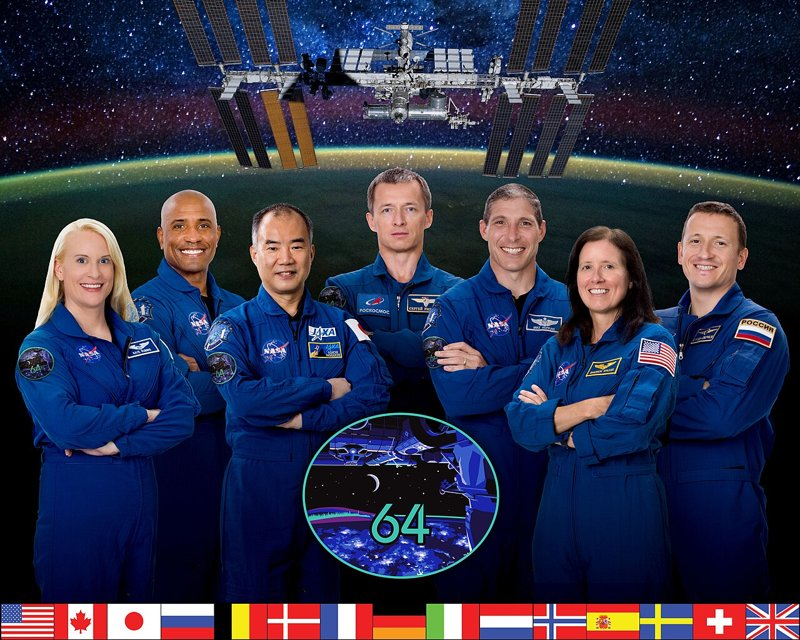

In [4]:
# A photo is a grid of pixels, and every pixel is three numbers: red, green and blue,
# from 0 to 255. np.array turns the image file into exactly that grid.
photo = np.array(Image.open("data/images/crew.jpg").convert("RGB"))

print("shape:", photo.shape, "  meaning (rows, columns, colours)")
print("the top-left pixel is", photo[0, 0], "  (red, green, blue)")


def show(image, width=800):
    """Display a grid of pixels as a picture, at most 800 pixels wide."""
    picture = Image.fromarray(image)
    picture.thumbnail((width, width))                  # shrink, keeping the proportions
    buffer = io.BytesIO()
    picture.save(buffer, format="JPEG", quality=85)    # JPEG keeps this notebook file small
    return Picture(buffer.getvalue())


show(photo)   # the last line of a cell is displayed: here, the photo itself

The crew of Expedition 64 on the International Space Station, an official NASA portrait
and therefore in the public domain. Seven faces, all looking at the camera, evenly lit:
the easiest possible case. We will make it harder later.

In [5]:
def find_faces(image, threshold=0.5):
    """Return every face in the image as (x, y, width, height, score)."""
    height, width = image.shape[:2]                # .shape[:2] is (rows, columns)
    face_detector.setInputSize((width, height))    # tell the detector this image's size
    face_detector.setScoreThreshold(threshold)     # drop anything it is less sure about

    # OpenCV stores colours as blue, green, red. Everything else in this notebook uses
    # red, green, blue, so we swap the order for this one call. Forgetting this swap is the
    # most common bug in computer vision code.
    _, found = face_detector.detect(cv2.cvtColor(image, cv2.COLOR_RGB2BGR))

    if found is None:                              # None means it found nothing
        return []
    # Each face is a row of 15 numbers: the box (x, y, width, height), then five points
    # (two eyes, the nose tip, two mouth corners), then the score at position 14.
    return [(int(f[0]), int(f[1]), int(f[2]), int(f[3]), float(f[14])) for f in found]


faces = find_faces(photo)
print("faces found:", len(faces))
for face in faces:
    print("   x, y, width, height, score =", face[:4], round(face[4], 2))

faces found: 7
   x, y, width, height, score = (924, 388, 78, 106) 0.94
   x, y, width, height, score = (595, 292, 84, 111) 0.94
   x, y, width, height, score = (778, 315, 84, 115) 0.94
   x, y, width, height, score = (410, 344, 86, 123) 0.93
   x, y, width, height, score = (102, 377, 82, 110) 0.93
   x, y, width, height, score = (263, 320, 83, 113) 0.93
   x, y, width, height, score = (1093, 344, 85, 115) 0.93


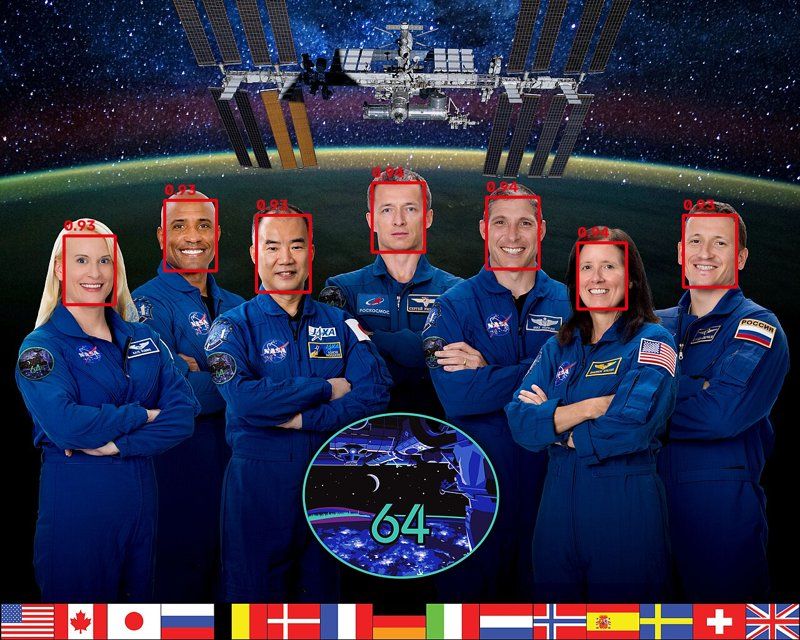

In [6]:
RED = (227, 6, 19)   # EhB red, as (red, green, blue)


def draw_boxes(image, boxes):
    """Draw each box with its score. Works on a copy, so the original stays untouched."""
    out = image.copy()
    for x, y, w, h, score in boxes:
        cv2.rectangle(out, (x, y), (x + w, y + h), RED, 3)   # 3 pixels thick
        cv2.putText(out, f"{score:.2f}", (x, y - 8), cv2.FONT_HERSHEY_SIMPLEX, 0.8, RED, 2)
    return out


show(draw_boxes(photo, faces))

---
## Part B, the score and the threshold

The detector does not say *face* or *no face*. It gives every candidate region a score
between 0 and 1, and the threshold decides which scores count. That threshold is your
decision, not the model's, and it is the most important number in this project.

In [7]:
# Run the detector at ten thresholds and count what comes back each time.
thresholds = [0.95, 0.9, 0.8, 0.6, 0.4, 0.3, 0.2, 0.15, 0.1, 0.05]
counts = [len(find_faces(photo, t)) for t in thresholds]

for t, n in zip(thresholds, counts):
    print(f"threshold {t:<5} faces {n}")

threshold 0.95  faces 0
threshold 0.9   faces 7
threshold 0.8   faces 7
threshold 0.6   faces 7
threshold 0.4   faces 7
threshold 0.3   faces 7
threshold 0.2   faces 7
threshold 0.15  faces 9
threshold 0.1   faces 12
threshold 0.05  faces 19


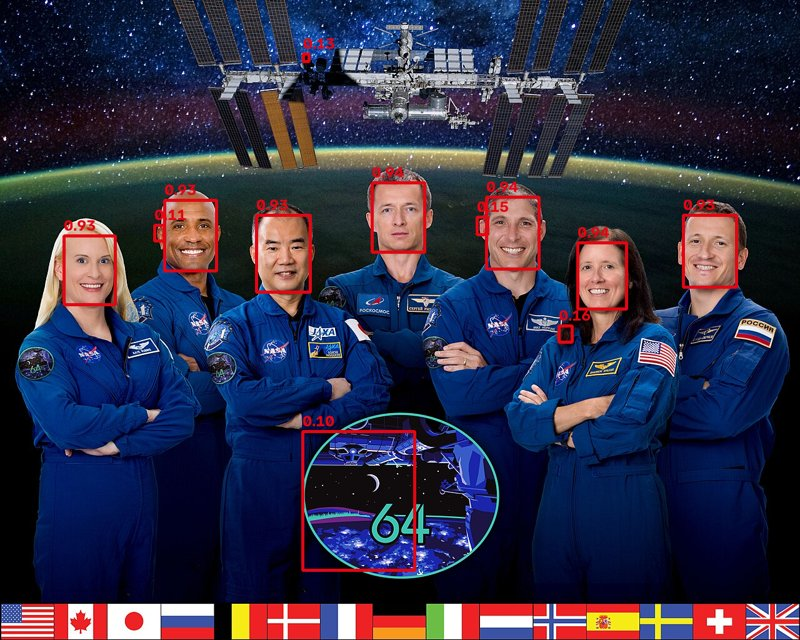

In [8]:
# Lower the threshold until the detector starts seeing faces that are not there.
show(draw_boxes(photo, find_faces(photo, threshold=0.1)))

From 0,2 to 0,9 you get exactly the seven astronauts. At 0,95 you get none at all: even a
perfect portrait scores 0,94. Below 0,2 the detector starts reporting faces on the mission
patch, the space station and spots on the uniforms. That is the trade-off from Session 2
again:

- a **high** threshold reports fewer false faces, and risks missing a real one
- a **low** threshold misses fewer real faces, and blurs some badges as well

For privacy the two mistakes are not equal. A blurred flag costs nothing. A missed face is
a person you published without consent. So for this job you pick a low threshold, and
accept some blurred badges. A different job, say counting visitors, would choose
differently. **The threshold encodes which mistake you can live with.**

In [9]:
# Where it really fails: change the photo, not the threshold.
# Each line makes one harder version, then counts the faces still found at 0.5.
harder = {
    "original": photo,
    "tiny, 12% of the size": cv2.resize(photo, None, fx=0.12, fy=0.12),
    "very dark, 8% of the light": (photo * 0.08).astype(np.uint8),
    "turned on its side": cv2.rotate(photo, cv2.ROTATE_90_CLOCKWISE),
    "upside down": cv2.rotate(photo, cv2.ROTATE_180),
}
for name, image in harder.items():
    print(f"{name:<28} {len(find_faces(image, 0.5))} of 7 faces")

original                     7 of 7 faces
tiny, 12% of the size        7 of 7 faces
very dark, 8% of the light   7 of 7 faces
turned on its side           5 of 7 faces
upside down                  7 of 7 faces


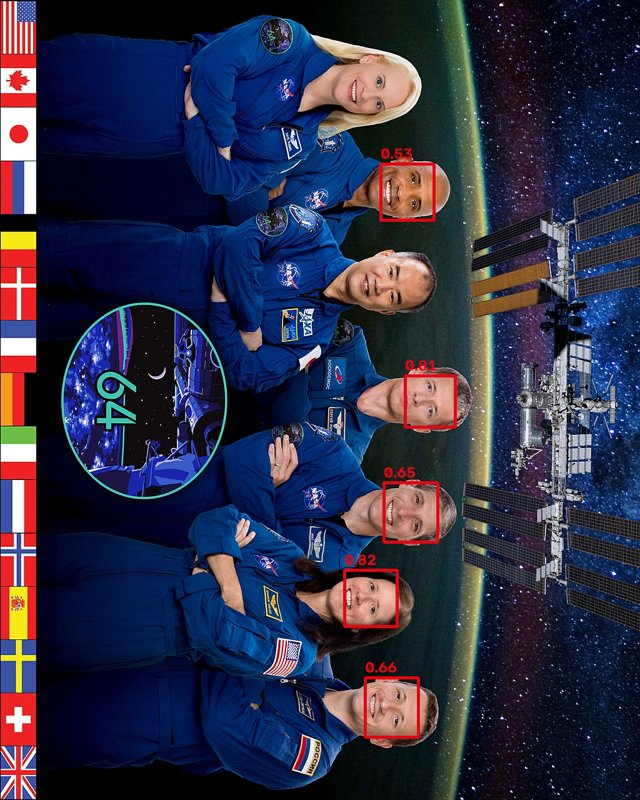

In [10]:
# See which two faces it lost when the photo is turned on its side.
sideways = harder["turned on its side"]
show(draw_boxes(sideways, find_faces(sideways, 0.5)))

Tiny and dark faces are fine: the training data was full of them. Faces lying on their
side are not, because people in photos are almost always upright. A model is good at what
its training data contained, and you only discover the gaps by testing cases like these.

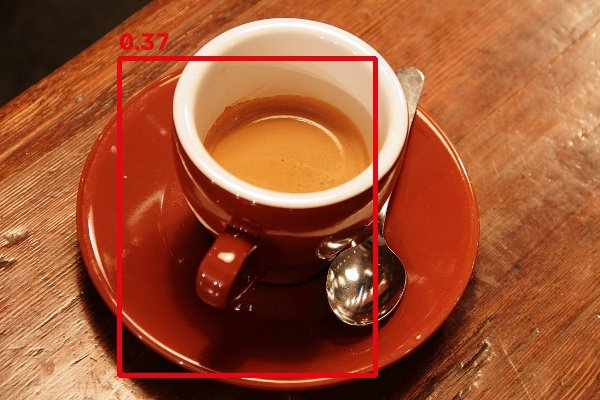

In [11]:
# One more: a cup of coffee. Is there a face in it?
coffee = np.array(Image.open("data/images/coffee.jpg").convert("RGB"))
show(draw_boxes(coffee, find_faces(coffee, 0.3)))

Below 0,4 the detector finds a face in the cup. People do this too, it is called
pareidolia: two dots and a curve and we see a face. The detector learned the same
pattern from the same kind of evidence.

**Exercise B1.** Find the highest threshold at which the sideways photo still gives all
seven faces. How many false faces does the upright photo show at that threshold?

**Exercise B2.** Try `ROTATE_90_COUNTERCLOCKWISE`, and a photo of your own. Put it in
`data/images` and change the file name in `Image.open`.

---
## Part C, hide what it found

Three ways to hide a face: blur it, pixelate it, or cover it. Two details matter more
than the choice between them:

- **make the box bigger** than the detector's box, because hair, ears and chin identify a person too
- **hide it hard**: a light blur can be undone, and people recognise friends from very little

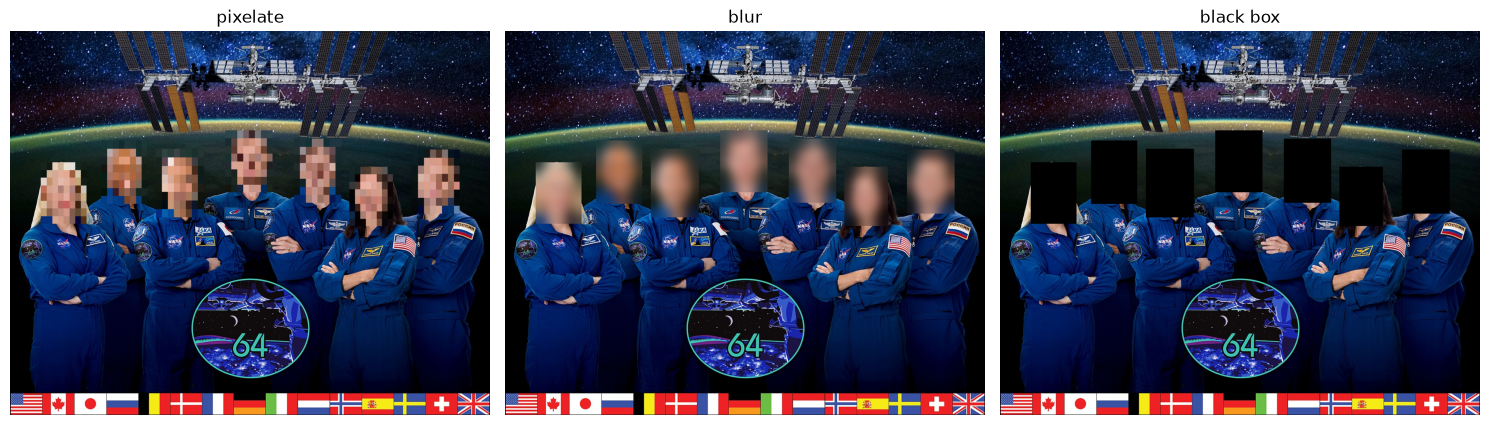

In [12]:
def hide_faces(image, faces, style="pixelate", margin=0.25):
    """Return a copy of the image with every face hidden."""
    out = image.copy()
    height, width = image.shape[:2]
    for x, y, w, h, _ in faces:            # the _ ignores the score: we hide them all
        # Grow the box by 25% on each side, without going past the edge of the image.
        dx, dy = int(w * margin), int(h * margin)
        x0, y0 = max(0, x - dx), max(0, y - dy)
        x1, y1 = min(width, x + w + dx), min(height, y + h + dy)
        region = out[y0:y1, x0:x1]         # rows y0 to y1, columns x0 to x1
        if region.size == 0:
            continue

        if style == "pixelate":
            # Shrink the face to 8 by 8 pixels, then blow it back up: big squares remain.
            tiny = cv2.resize(region, (8, 8), interpolation=cv2.INTER_LINEAR)
            out[y0:y1, x0:x1] = cv2.resize(tiny, (x1 - x0, y1 - y0), interpolation=cv2.INTER_NEAREST)
        elif style == "blur":
            # A Gaussian blur averages each pixel with its neighbours. 99 is the width of
            # the neighbourhood, in pixels: the bigger, the blurrier. It must be odd.
            out[y0:y1, x0:x1] = cv2.GaussianBlur(region, (99, 99), 0)
        else:
            out[y0:y1, x0:x1] = 0          # black box: every number set to 0
    return out


# Three versions side by side. plt.subplots(1, 3) makes one row of three panels.
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, style in zip(axes, ["pixelate", "blur", "black box"]):
    ax.imshow(hide_faces(photo, find_faces(photo, 0.3), style))
    ax.set_title(style)
    ax.axis("off")
plt.tight_layout()
plt.show()

**Exercise C1.** Change the 8 in the pixelate line to 16, then to 4. From which size can
you still tell the astronauts apart?

**Exercise C2.** Set `margin=0`. What is left visible around each face?

---
## Part D, live, on your webcam

Same two functions, now on every frame of your webcam. The app below is built with
**Gradio**, a library that turns a Python function into a small web page. It opens in your
browser, which asks for permission to use the camera.

Everything runs on your own laptop: the page talks to this notebook and nothing is sent
anywhere else.

In [13]:
import gradio as gr


def protect(frame, threshold, style):
    """Called for every webcam frame: find the faces, hide them, return the result."""
    if frame is None:              # the first call can come before the camera has started
        return None
    return hide_faces(frame, find_faces(frame, threshold), style)


# gr.Blocks() is the page. Everything created inside the "with" ends up on it, top to bottom.
with gr.Blocks(title="Privacy blur") as privacy_app:
    gr.Markdown("## Privacy blur\nAllow the camera, then press **Record**. Try turning your head.")
    with gr.Row():                                         # a row puts things side by side
        camera = gr.Image(sources=["webcam"], streaming=True, label="Webcam")
        result = gr.Image(label="What gets stored")
    threshold = gr.Slider(0.05, 0.95, value=0.3, step=0.05, label="Threshold")
    style = gr.Radio(["pixelate", "blur", "black box"], value="pixelate", label="Style")

    # .stream() sends a frame to protect() ten times a second, and shows what comes back.
    camera.stream(protect, inputs=[camera, threshold, style], outputs=result, stream_every=0.1)

# This opens the page in your browser. If it does not open by itself, click the link
# printed below. The app keeps running until you run privacy_app.close() or restart.
privacy_app.launch(inbrowser=True, inline=False)

* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.


Things to try, in this order:

1. Turn your head slowly to the side. At which angle does the blur fall off?
2. Hold a phone up with a photo of a face on it. Is that a face?
3. Move the threshold up to 0,9, then down to 0,05, and watch the false faces appear
4. Cover half your face with your hand

In [14]:
# Stop the app when you are done, so the camera is released.
privacy_app.close()

Closing server running on port: 7860


---
## Part E, from faces to anything: count the people in a room

YuNet knows one thing. **RT-DETR**, a detector from Peking University and Baidu, knows 80:
people, cups, laptops, phones, chairs, bicycles... It was trained on COCO, more than
200.000 photos in which people drew a box around every object. It is 80 MB, and Hugging Face
`transformers` loads it in one line.

The use case: a room has a maximum number of people, for fire safety or for a booking
system. Count them, without storing anybody's face.

In [15]:
from collections import Counter  # counts how often each item appears in a list

from transformers import pipeline

# pipeline(task, model) downloads the model the first time and wraps it in a function.
object_detector = pipeline("object-detection", model="PekingU/rtdetr_v2_r18vd")

found = object_detector(Image.fromarray(photo), threshold=0.5)
print("first result:", found[0])
print()
print(Counter(item["label"] for item in found))

first result: {'score': 0.9559776186943054, 'label': 'person', 'box': {'xmin': 24, 'ymin': 348, 'xmax': 317, 'ymax': 967}}

Counter({'person': 7, 'cell phone': 1})


Seven people, and one `cell phone` that is not there. Look at the picture below to see
what it took for a phone. The same lesson as Part B: every detector has a threshold, and
every threshold lets something through.

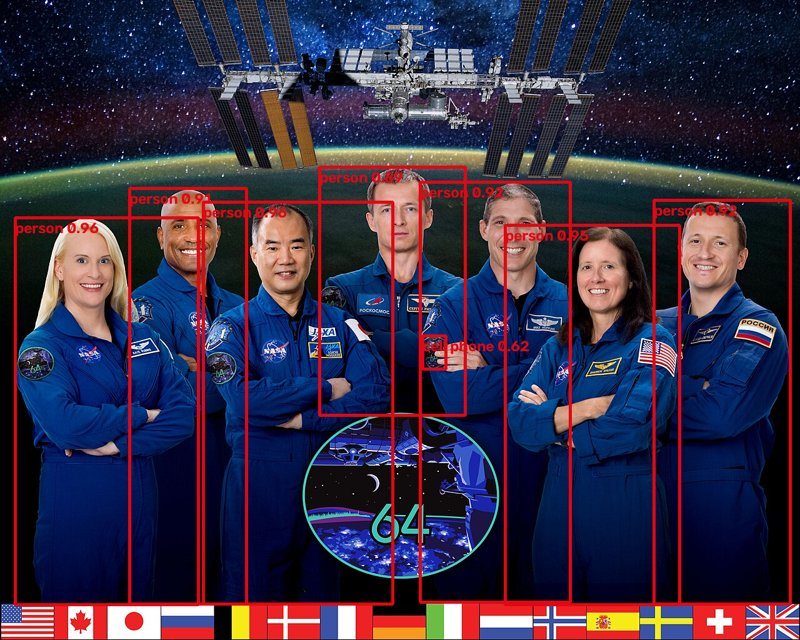

In [16]:
def draw_objects(image, found):
    """Draw RT-DETR's results: a box, the label and the score."""
    out = image.copy()
    for item in found:
        b = item["box"]   # a dictionary with xmin, ymin, xmax, ymax
        cv2.rectangle(out, (b["xmin"], b["ymin"]), (b["xmax"], b["ymax"]), RED, 3)
        cv2.putText(out, f'{item["label"]} {item["score"]:.2f}', (b["xmin"], b["ymin"] + 25),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.8, RED, 2)
    return out


show(draw_objects(photo, found))

### The room counter

Two decisions in one app. The detector counts; your code compares the count with the
limit. The faces are hidden before the frame is shown, so this counter could run on a
screen at the door without showing anybody.

In [17]:
def count_room(frame, what, limit, threshold):
    """Count one kind of object in the frame, hide the faces, and report against the limit."""
    if frame is None:
        return None, ""
    found = [x for x in object_detector(Image.fromarray(frame), threshold=threshold)
             if x["label"] == what]
    shown = draw_objects(hide_faces(frame, find_faces(frame, 0.3)), found)
    n = len(found)
    status = f"## {n} × {what}" + (f"  \n**Over the limit of {limit}**" if n > limit else f"  \nlimit {limit}")
    return shown, status


labels = sorted(object_detector.model.config.id2label.values())   # all 80 things it knows

with gr.Blocks(title="Room counter") as counter_app:
    gr.Markdown("## Room counter")
    with gr.Row():
        camera = gr.Image(sources=["webcam"], streaming=True, label="Webcam")
        with gr.Column():                                  # a column stacks things vertically
            shown = gr.Image(label="Counted")
            status = gr.Markdown()
    what = gr.Dropdown(labels, value="person", label="Count")
    limit = gr.Number(value=2, precision=0, label="Limit")
    threshold = gr.Slider(0.1, 0.9, value=0.5, step=0.05, label="Threshold")
    camera.stream(count_room, inputs=[camera, what, limit, threshold], outputs=[shown, status],
                  stream_every=0.2)

counter_app.launch(inbrowser=True, inline=False)

* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.


In [18]:
counter_app.close()

Closing server running on port: 7860


**Exercise E1.** Switch the count to `cup`, `cell phone` or `book`, and hold things up.
Which ones does it find reliably? Which ones does it confuse?

**Exercise E2.** Invent a use for counting one kind of object. A shop shelf with too few
bottles? A bicycle shed? A desk with a phone on it during study time? Write down which
mistake would hurt more in your use, a missed object or a false one, and set the threshold
to match.

---
## What to take from this

**Detection is not recognition.** Everything here finds *a* face; nothing finds *whose*
face. That line matters in law. The EU AI Act bans scraping faces from the internet or
CCTV to build recognition databases, bans emotion recognition at work and in education,
and allows real-time identification of people in public spaces by the police only in a few
narrow cases. Blurring faces is the opposite use: it protects people.

**You downloaded the intelligence, and kept the responsibility.** You chose the threshold,
the margin around each face and the strength of the blur. You also found the failure (a
face on its side) by testing, not by reading the documentation.

Images: Expedition 64 crew portrait, NASA, public domain. Coffee photo by Rachel Michetti,
CC0, from the scikit-image sample data.